# Member 1: Data Processing and Product Recommendation
This notebook cleans and merges the customer datasets, explores purchasing patterns, trains a product recommendation model, and saves the files needed.

## 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from pathlib import Path
from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, log_loss, classification_report, ConfusionMatrixDisplay



import sys

if "google.colab" in sys.modules:
    ROOT = Path("/content/multimodal-recommendation-system")
else:
    ROOT = Path.cwd()
    if not (ROOT / "datasets").exists():
        ROOT = ROOT.parent

DATA_DIR = ROOT / "datasets"
MODEL_DIR = ROOT / "models"
SRC_DIR = ROOT / "src"
for folder in [DATA_DIR, MODEL_DIR, SRC_DIR, ROOT / "notebooks"]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project folder:", ROOT)

Project folder: /content/multimodal-recommendation-system


## Set up CSV files

In [2]:
if "google.colab" in sys.modules:
    from google.colab import files
    print("Select both CSV files from your computer:")
    uploaded = files.upload()
    for filename, content in uploaded.items():
        (DATA_DIR / filename).write_bytes(content)

print("Transactions file exists:", (DATA_DIR / "customer_transactions.csv").exists())
print("Social profiles file exists:", (DATA_DIR / "customer_social_profiles.csv").exists())

Select both CSV files from your computer:


Saving customer_social_profiles.csv to customer_social_profiles.csv
Saving customer_transactions.csv to customer_transactions.csv
Transactions file exists: True
Social profiles file exists: True


## 2. Load and explore the datasets
First, I checked the data types, missing values, duplicates and basic statistics.

In [3]:
transactions = pd.read_csv(DATA_DIR / "customer_transactions.csv")
social = pd.read_csv(DATA_DIR / "customer_social_profiles.csv")

print("Transactions shape:", transactions.shape)
print("Social profiles shape:", social.shape)

display(transactions.head(), social.head())

print("Transaction column types:")
print(transactions.dtypes)

print("Social profile column types:")
print(social.dtypes)

print("Missing values in transactions:\n", transactions.isna().sum())
print("Missing values in social profiles:\n", social.isna().sum())

print("Exact duplicates:", transactions.duplicated().sum(), "transactions and", social.duplicated().sum(), "social profiles")
display(transactions.describe(include="all"), social.describe(include="all"))

Transactions shape: (150, 6)
Social profiles shape: (155, 5)


,customer_id_legacy,transaction_id,purchase_amount,purchase_date,product_category,customer_rating
0,151,1001,408,2024-01-01,Sports,2.3
1,192,1002,332,2024-01-02,Electronics,4.2
2,114,1003,442,2024-01-03,Electronics,2.1
3,171,1004,256,2024-01-04,Clothing,2.8
4,160,1005,64,2024-01-05,Clothing,1.3


,customer_id_new,social_media_platform,engagement_score,purchase_interest_score,review_sentiment
0,A178,LinkedIn,74,4.9,Positive
1,A190,Twitter,82,4.8,Neutral
2,A150,Facebook,96,1.6,Positive
3,A162,Twitter,89,2.6,Positive
4,A197,Twitter,92,2.3,Neutral


Transaction column types:
customer_id_legacy      int64
transaction_id          int64
purchase_amount         int64
purchase_date          object
product_category       object
customer_rating       float64
dtype: object
Social profile column types:
customer_id_new             object
social_media_platform       object
engagement_score             int64
purchase_interest_score    float64
review_sentiment            object
dtype: object
Missing values in transactions:
 customer_id_legacy     0
transaction_id         0
purchase_amount        0
purchase_date          0
product_category       0
customer_rating       10
dtype: int64
Missing values in social profiles:
 customer_id_new            0
social_media_platform      0
engagement_score           0
purchase_interest_score    0
review_sentiment           0
dtype: int64
Exact duplicates: 0 transactions and 5 social profiles


,customer_id_legacy,transaction_id,purchase_amount,purchase_date,product_category,customer_rating
count,150.000000,150.000000,150.000000,150,150,140.00000
unique,NaN,NaN,NaN,150,5,NaN
top,NaN,NaN,NaN,2024-01-01,Sports,NaN
freq,NaN,NaN,NaN,1,35,NaN
mean,148.760000,1075.500000,280.780000,NaN,NaN,2.98500
std,30.046425,43.445368,121.329595,NaN,NaN,1.20699
min,100.000000,1001.000000,51.000000,NaN,NaN,1.00000
25%,121.250000,1038.250000,179.000000,NaN,NaN,1.95000
50%,150.500000,1075.500000,274.000000,NaN,NaN,3.00000
75%,174.750000,1112.750000,388.500000,NaN,NaN,4.00000


,customer_id_new,social_media_platform,engagement_score,purchase_interest_score,review_sentiment
count,155,155,155.000000,155.000000,155
unique,84,5,NaN,NaN,3
top,A155,Twitter,NaN,NaN,Positive
freq,7,38,NaN,NaN,63
mean,NaN,NaN,75.606452,3.152903,NaN
std,NaN,NaN,14.568021,1.142867,NaN
min,NaN,NaN,50.000000,1.000000,NaN
25%,NaN,NaN,63.500000,2.350000,NaN
50%,NaN,NaN,77.000000,3.200000,NaN
75%,NaN,NaN,87.500000,4.100000,NaN


## 3. Clean both datasets
The two files use different customer ID formats. I made them consistent and removed exact duplicates. Missing ratings are filled with the median for analysis, but ratings will not be used to predict a future purchase.

In [4]:
transactions = transactions.drop_duplicates().copy()
social = social.drop_duplicates().copy()

transactions["customer_id"] = pd.to_numeric(transactions["customer_id_legacy"], errors="coerce")
social["customer_id"] = pd.to_numeric(social["customer_id_new"].astype(str).str.extract(r"(\d+)$")[0], errors="coerce")
transactions["purchase_date"] = pd.to_datetime(transactions["purchase_date"], errors="coerce")

for column in ["purchase_amount", "customer_rating"]:
    transactions[column] = pd.to_numeric(transactions[column], errors="coerce")

for column in ["engagement_score", "purchase_interest_score"]:
    social[column] = pd.to_numeric(social[column], errors="coerce")

for column in ["product_category"]:
    transactions[column] = transactions[column].astype("string").str.strip().str.title()

for column in ["social_media_platform", "review_sentiment"]:
    social[column] = social[column].astype("string").str.strip().str.title()

transactions = transactions.dropna(subset=["customer_id", "transaction_id", "product_category", "purchase_date"])
social = social.dropna(subset=["customer_id"])

transactions["customer_id"] = transactions["customer_id"].astype(int)
social["customer_id"] = social["customer_id"].astype(int)

transactions["customer_rating"] = transactions["customer_rating"].fillna(transactions["customer_rating"].median())
transactions["purchase_amount"] = transactions["purchase_amount"].fillna(transactions["purchase_amount"].median())

for column in ["engagement_score", "purchase_interest_score"]:
    social[column] = social[column].fillna(social[column].median())

for column in ["social_media_platform", "review_sentiment"]:
    social[column] = social[column].fillna("Unknown")

print("Cleaned transactions:", len(transactions))
print("Cleaned social profiles:", len(social))
print("Missing values after cleaning:", transactions.isna().sum().sum(), social.isna().sum().sum())

Cleaned transactions: 150
Cleaned social profiles: 150
Missing values after cleaning: 0 0


## 4. Merge and check the results
Some customers have more than one social profile. I summarized their social activity first, so each transaction matches only one customer profile.

In [5]:
def most_common(values):
    return values.mode().iloc[0] if not values.mode().empty else "Unknown"

social_summary = social.groupby("customer_id", as_index=False).agg(
    engagement_score=("engagement_score", "mean"),
    purchase_interest_score=("purchase_interest_score", "mean"),
    social_profile_count=("customer_id", "size"),
    social_media_platform=("social_media_platform", most_common),
    review_sentiment=("review_sentiment", most_common)
)
merged = transactions.merge(social_summary, on="customer_id", how="left", validate="many_to_one", indicator=True)

print("Transactions before merge:", len(transactions))
print("Rows after merge:", len(merged))
print("Merge results:\n", merged["_merge"].value_counts())
print("Unmatched customer IDs:", merged.loc[merged["_merge"] == "left_only", "customer_id"].nunique())

assert len(merged) == len(transactions)
assert merged["transaction_id"].is_unique

merged = merged.drop(columns="_merge")
merged["social_profile_count"] = merged["social_profile_count"].fillna(0).astype(int)

for column in ["social_media_platform", "review_sentiment"]:
    merged[column] = merged[column].fillna("Unknown")

for column in ["engagement_score", "purchase_interest_score"]:
    merged[column] = merged[column].fillna(social_summary[column].median())

merged["purchase_month"] = merged["purchase_date"].dt.month
merged["purchase_day_of_week"] = merged["purchase_date"].dt.dayofweek
merged["high_engagement"] = (merged["engagement_score"] >= merged["engagement_score"].median()).astype(int)

print("Final merged dataset:", merged.shape)
print("Remaining missing values:", merged.isna().sum().sum())
display(merged.head())

Transactions before merge: 150
Rows after merge: 150
Merge results:
 _merge
both          117
left_only      33
right_only      0
Name: count, dtype: int64
Unmatched customer IDs: 14
Final merged dataset: (150, 15)
Remaining missing values: 0


,customer_id_legacy,transaction_id,purchase_amount,purchase_date,product_category,customer_rating,customer_id,engagement_score,purchase_interest_score,social_profile_count,social_media_platform,review_sentiment,purchase_month,purchase_day_of_week,high_engagement
0,151,1001,408,2024-01-01,Sports,2.3,151,71.666667,2.166667,3,Twitter,Neutral,1,0,0
1,192,1002,332,2024-01-02,Electronics,4.2,192,60.000000,4.300000,1,Instagram,Positive,1,1,0
2,114,1003,442,2024-01-03,Electronics,2.1,114,87.000000,4.800000,1,Facebook,Negative,1,2,1
3,171,1004,256,2024-01-04,Clothing,2.8,171,75.833333,3.250000,0,Unknown,Unknown,1,3,1
4,160,1005,64,2024-01-05,Clothing,1.3,160,72.666667,2.500000,3,Instagram,Neutral,1,4,0


## 5. Explore customer purchasing patterns
I used a category distribution, a purchase amount boxplot and a correlation heatmap. These help identify popular products, unusual amounts and relationships between numerical variables.

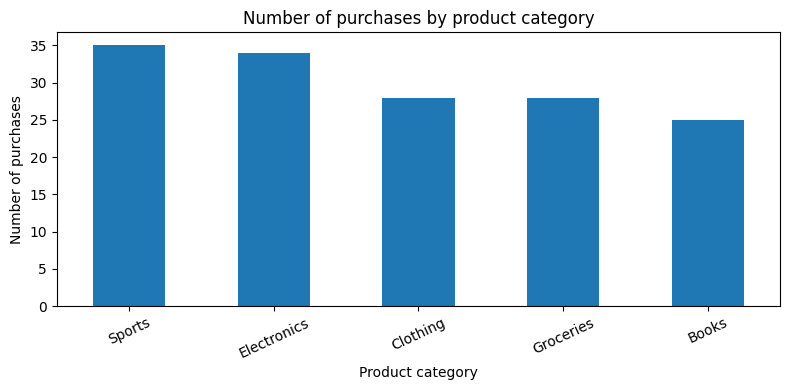

Most purchased category: Sports


In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
merged["product_category"].value_counts().plot(kind="bar", ax=ax)

ax.set(title="Number of purchases by product category", xlabel="Product category", ylabel="Number of purchases")

plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

print("Most purchased category:", merged["product_category"].value_counts().idxmax())

The bar chart shows how many purchases belong to each product category. Sports has the most purchases, but the categories are fairly close in size.

<Figure size 700x400 with 0 Axes>

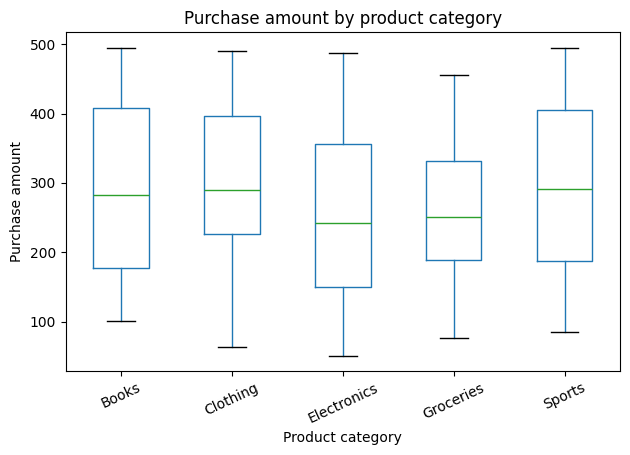

Purchase amount range: 51 to 495


In [7]:
plt.figure(figsize=(7, 4))
merged.boxplot(column="purchase_amount", by="product_category", grid=False)

plt.suptitle("")
plt.title("Purchase amount by product category")
plt.xlabel("Product category")
plt.ylabel("Purchase amount")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

print("Purchase amount range:", merged["purchase_amount"].min(), "to", merged["purchase_amount"].max())

The boxplot compares purchase amounts across categories and helps us see the spread and any unusual values.

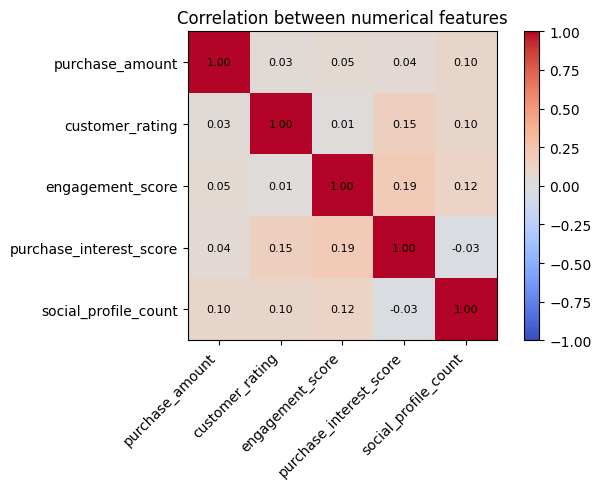

The heatmap shows which numerical features move together. Correlation does not prove causation.


In [8]:
numeric_columns = ["purchase_amount", "customer_rating", "engagement_score", "purchase_interest_score", "social_profile_count"]
plt.figure(figsize=(7, 5))
corr = merged[numeric_columns].corr()

plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(numeric_columns)), numeric_columns, rotation=45, ha="right")
plt.yticks(range(len(numeric_columns)), numeric_columns)

for i in range(len(numeric_columns)):
    for j in range(len(numeric_columns)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)

plt.title("Correlation between numerical features")
plt.tight_layout()
plt.show()
print("The heatmap shows which numerical features move together. Correlation does not prove causation.")

The heatmap compares numerical columns. A strong correlation between inputs does not automatically mean they predict the purchased category.

## 6. Prepare features for the model
The target is the purchased product category. I used social activity as the input because transaction amount, rating and purchase date would not be known before a future purchase. I split by customer so the same customer does not appear in both training and testing.

In [9]:
features = ["engagement_score", "purchase_interest_score", "social_profile_count", "high_engagement", "social_media_platform", "review_sentiment"]

numeric_features = ["engagement_score", "purchase_interest_score", "social_profile_count", "high_engagement"]
categorical_features = ["social_media_platform", "review_sentiment"]

X = merged[features]
y = merged["product_category"].astype(str)

splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
train_index, test_index = next(splitter.split(X, y, groups=merged["customer_id"]))

X_train, X_test = X.iloc[train_index], X.iloc[test_index]
y_train, y_test = y.iloc[train_index], y.iloc[test_index]

print("Training rows:", len(X_train), "Testing rows:", len(X_test))
print("Customers in both sets:", len(set(merged.iloc[train_index]["customer_id"]) & set(merged.iloc[test_index]["customer_id"])))
print("Training categories:\n", y_train.value_counts())
print("Testing categories:\n", y_test.value_counts())

Training rows: 119 Testing rows: 31
Customers in both sets: 0
Training categories:
 product_category
Electronics    29
Sports         27
Groceries      24
Books          22
Clothing       17
Name: count, dtype: int64
Testing categories:
 product_category
Clothing       11
Sports          8
Electronics     5
Groceries       4
Books           3
Name: count, dtype: int64


### Simple baseline comparison
I also checked what happens if we always predict the most common category from the training data. This gives us a simple result to compare with Random Forest.

In [10]:
most_common_category = y_train.mode()[0]
baseline_predictions = [most_common_category] * len(y_test)

print("Baseline category:", most_common_category)
print("Baseline accuracy:", round(accuracy_score(y_test, baseline_predictions), 4))

Baseline category: Electronics
Baseline accuracy: 0.1613


## 7. Train the product recommendation model
I used Random Forest because it can work with different kinds of customer features. The pipeline also handles missing inputs and converts category labels into numbers internally.

In [11]:
preprocessing = ColumnTransformer([
    ("numbers", SimpleImputer(strategy="median"), numeric_features),
    ("categories", Pipeline([
        ("fill", SimpleImputer(strategy="most_frequent")),
        ("encode", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features)
])

model = Pipeline([
    ("preprocessing", preprocessing),
    ("classifier", RandomForestClassifier(n_estimators=100, random_state=42, min_samples_leaf=2))
])

model.fit(X_train, y_train)
print("Model trained successfully.")

Model trained successfully.


## 8. Evaluate the model
Accuracy shows the proportion of correct predictions. Precision, recall and F1 give a fuller picture across product categories. Log loss checks how confident the predicted probabilities are. Low scores may mean the social features are not strong predictors of product choice.

Accuracy: 0.1613
Precision (weighted): 0.2419
Recall (weighted): 0.1613
F1-score (weighted): 0.1352
Log loss: 1.7599

Classification report:
               precision    recall  f1-score   support

       Books       0.00      0.00      0.00         3
    Clothing       0.50      0.09      0.15        11
 Electronics       0.20      0.60      0.30         5
   Groceries       0.00      0.00      0.00         4
      Sports       0.12      0.12      0.12         8

    accuracy                           0.16        31
   macro avg       0.16      0.16      0.12        31
weighted avg       0.24      0.16      0.14        31



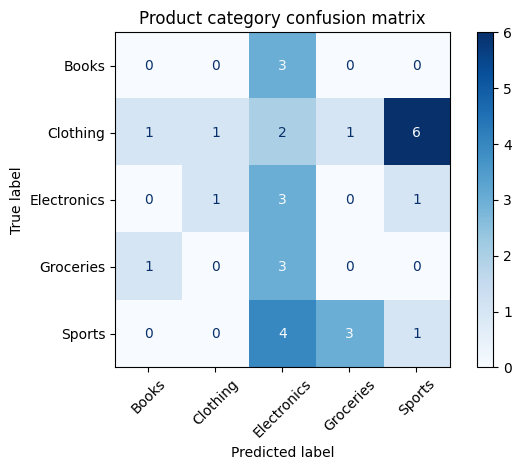

In [13]:
predictions = model.predict(X_test)
probabilities = model.predict_proba(X_test)

print("Accuracy:", round(accuracy_score(y_test, predictions), 4))
print("Precision (weighted):", round(precision_score(y_test, predictions, average="weighted", zero_division=0), 4))

print("Recall (weighted):", round(recall_score(y_test, predictions, average="weighted", zero_division=0), 4))
print("F1-score (weighted):", round(f1_score(y_test, predictions, average="weighted", zero_division=0), 4))

print("Log loss:", round(log_loss(y_test, probabilities, labels=model.classes_), 4))
print("\nClassification report:\n", classification_report(y_test, predictions, zero_division=0))

ConfusionMatrixDisplay.from_predictions(y_test, predictions, labels=model.classes_, xticks_rotation=45, cmap="Blues")

plt.title("Product category confusion matrix")
plt.tight_layout()
plt.show()

## 9. Save the dataset and final model
The model is saved together with its preprocessing steps. The group can use the customer ID to request a prediction through the Python script.

In [14]:
merged.to_csv(DATA_DIR / "merged_dataset.csv", index=False)
joblib.dump(model, MODEL_DIR / "product_model.pkl")

print("Saved merged_dataset.csv and product_model.pkl")
print("Model input columns:", model.feature_names_in_.tolist())
print("Example customer ID:", merged["customer_id"].iloc[0])

Saved merged_dataset.csv and product_model.pkl
Model input columns: ['engagement_score', 'purchase_interest_score', 'social_profile_count', 'high_engagement', 'social_media_platform', 'review_sentiment']
Example customer ID: 151


## 10. Check a sample prediction
This confirms that the saved model can be loaded and used to predict a product for a known customer.

In [15]:
saved_model = joblib.load(MODEL_DIR / "product_model.pkl")
sample_customer = int(merged["customer_id"].iloc[0])
sample_features = merged.loc[merged["customer_id"] == sample_customer, features].head(1)

print("Customer ID:", sample_customer)
print("Predicted product:", saved_model.predict(sample_features)[0])
print("Note: This is a predicted category, not a guaranteed purchase.")

Customer ID: 151
Predicted product: Sports
Note: This is a predicted category, not a guaranteed purchase.


## 11. Test the prediction function
This function will be used when connecting the models. I tested a valid ID, an ID starting with A, and an unknown customer.

In [19]:
# test the prediction function
if (SRC_DIR / "product_recommendation.py").exists():
    if str(SRC_DIR) not in sys.path:
        sys.path.insert(0, str(SRC_DIR))
    from product_recommendation import predict_product
    sample_customer = int(merged["customer_id"].iloc[0])
    print("Customer", sample_customer, ":", predict_product(sample_customer))
    print("Customer A" + str(sample_customer) + ":", predict_product("A" + str(sample_customer)))
    try:
        predict_product(999999)
    except ValueError as error:
        print("Unknown customer:", error)
else:
    print("Test the prediction script after adding it to src/.")

Customer 151 : Sports
Customer A151: Sports
Unknown customer: Customer 999999 was not found
